# Final Project

**Submitted by:**

| Name | ID |
|---|---|
| Neta Ronen | 318595956 |
| Elav Cohen | 208698100 |

**Data:** CDC Behavioral Risk Factor Surveillance System (BRFSS), 2022

### Research question

Our research question is: **How well can insufficient sleep be predicted from structural characteristics alone — age, sex, race/ethnicity, income, education, employment, marital status, and geography — before any health variable is added, and how much does prediction improve when lifestyle and health variables are added?**

Our original research question was: *Which demographic, socioeconomic, lifestyle, and health-related factors are most strongly associated with insufficient sleep among adults in the United States, and how accurately can insufficient sleep be predicted from these factors?*

We changed the question because the original one has already been answered in previous studies.

### Background

Insufficient sleep is defined as reporting fewer than seven hours of sleep in a typical 24-hour period, following the CDC's official definition for adults. The intended audience includes public-health organizations, healthcare professionals, and policy makers. Because BRFSS is a cross-sectional survey, the project describes associations and predictive patterns; no causal claims are made.

The question is addressed by training and comparing two models: Model 1 uses only structural/demographic variables; Model 2 adds lifestyle and health variables. Both models use the same algorithms, the same respondents, and the same data split. The performance gap between the two models is the main finding.

### Data

We use two files from the CDC Behavioral Risk Factor Surveillance System (BRFSS), in SAS Transport (XPT) format:

| File | Used for | Source |
|---|---|---|
| BRFSS 2022 (`LLCP2022.XPT`) | All analysis and models | [CDC BRFSS 2022](https://www.cdc.gov/brfss/annual_data/annual_2022.html) |
| BRFSS 2020 (`LLCP2020.XPT`) | Validation only: reproducing the CDC's published prevalence | [CDC BRFSS 2020](https://www.cdc.gov/brfss/annual_data/annual_2020.html) |

The files are too large to submit (about 1 GB each), so the next cell downloads them from the CDC if they are missing.

Codes and variable definitions are taken from the [2022 BRFSS Codebook](https://www.cdc.gov/brfss/annual_data/2022/zip/codebook22_llcp-v2-508.zip) and the [2022 Calculated Variables document](https://www.cdc.gov/brfss/annual_data/2022/pdf/2022-calculated-variables-version4-508.pdf).

### Methods
• Methods — the steps you took to answer the question, including the packages and parameters you used


### Results
• Results — a coherent description of your findings, with figures and tables (move very large tables to an appendix)


### Discussion
 Discussion — what your results mean, whether your approach was appropriate, what you would do differently, what
remains unknown, and how you would address it. If you could not answer the question, explain why and what would be
needed to answer it


### AI
we used Claude Opus 4.1 to help us with the project.

we used it to debuging, drfting texts, planning the work.

**list of prompts we used:**
- Hi, i aent to write part 3 of the task lets start with a title and the submiters deatels
- now add the backgrond pergraph it should be short and somthing like: Insufficient sleep is defined as reporting fewer than seven hours of sleep in a typical 24-hour period, following the CDC's official definition for adults. The intended audience includes public-health organizations, healthcare professionals, and policy makers. Because BRFSS is a cross-sectional survey, the project describes associations and predictive patterns; no causal claims are made.
The question is addressed by training and comparing two models: Model 1 uses only structural/demographic variables; Model 2 adds lifestyle and health variables. The performance gap between the two models is the main finding, and it directly answers a question the existing literature has not resolved in a two-stage framework on this dataset.
- now add the question Our research question is: How much of insufficient sleep can be explained by structural characteristics alone — age, sex, race/ethnicity, income, education, employment, marital status, and geography — and how much additional explanatory power is gained by adding self-reported lifestyle and health variables? and write that our origin question was: Our research question is: Which demographic, socioeconomic, lifestyle, and health-related factors are most strongly associated with insufficient sleep among adults in the United States, and how accurately can insufficient sleep be predicted from these factors? and that we chnages becouse it was answered already
- in a new cell benth the backgeon cell downlaod the 2 files 2022 BRFSS Codebook (ZIP, 3 MB) Calculated Variables (PDF) and the The BRFSS 2020 file
- add a cell about the data we used and the files we downloaded:
  - we used the 2022 BRFSS data file
  - we used the 2020 BRFSS data file for validation
  - we used the 2022 BRFSS Codebook Calculated Variables to understand the data
- what dose background/EDA mean?
- add a setup cell - that import pandas numpy scikit-learn mtplotlib scipy print the version of all of them set random seed to 42 . defien the LLCP2022XPT/LLCP2022.XPT", "LLCP2020XPT/LLCP2020.XPT" files
-make sure the two data files are on the computer and if its missing load it from CDC website
- load the BRFSS 2022 XPT file.  read it in chunks and keep only the columns we need: the sleep question, the Group A and Group B variables, the state and the survey weight. Then check that we got 445,132 rows, that the raw file has 328 columns, and that none of our columns are missing.
-  Load the BRFSS 2020 file, keep only the 50 states and DC, build the insufficient-sleep variable the same way as for 2022, and calculate the weighted percentage with the survey weight. Compare it to the CDC's published 32.7%  
- Clean the data-  Replace all the don't know, refused and missing codes with NaN, turn 88 into 0 for the mental and physical health questions.
 Create the target: 1 if sleeps less than 7 hours 0 otherwise,  drop people with no valid sleep  group the states into the 4 census regions plus a territories group. . every code must be checked against the BRFSS 2022 codebook
 - chnage MENTHLTH  PHYSHLTH _DRNKWK2  to 0 , remove invalid answer to the sleep coulmn, do yu think that thrre are more thing to remive or chnage? Check for duplicate rows
 - crate a table with all the cleaning destions you did
 - in the next cell show what percent of people sleep less than 7 hours, with and without the weights. Plot a histogram with aline at 7
 Make bar charts of the insufficient sleep rate by age, sex, income, education, race, region, and by general health and depression
make a correlation heatmap, run chi-square tests
label them as exploratory only
- how balanced the two classes are?
-  Add a  baseline that always predicts 'sufficient sleep' Show its accuracy, precision, recall, F1, ROC-AUC and Average Precision on the validation set
- train Model 1 using  Group A background variables. Use Logistic Regression, Random Forest and Gradient Boosting. Tune them with a random search of 20 combinations, training on the train set, scoring on the validation set, and using Average Precision as the score  
 - pick the best decision threshold on the validation set by maximizing F1 and check that the models aren't overfitting
- do the same thing for Model 2, using Group A plus the Group B health and lifestyle variables. Keep everything else the same as in Model 1
- evaluate all 6 models (3 algorithms × 2 feature sets) on the test set, once, with the settings and thresholds. Show accuracy, precision, recall, F1, ROC-AUC, Average Precision and a confusion matrix for each.
- Plot ROC curves and precision-recall curves comparing Model 1 and Model 2 for each algorithm.
- Make one main table with the Model 1 score, the Model 2 score and the difference for each algorithm
-help me write alll the graphs results in a new section without conclotions




# notebook

### Exploratory Data Analysis
This part loads, checks and cleans the data and explores it with tables and plots. We do this first so that we understand the data, and fix its problems, before building any model. we set the random forst to 42 for reproducibility, so the results are consistent.

In [ ]:
# Setup: libraries, versions, random seed and data file paths.
# We print the library versions so anyone can reproduce our results with the same versions.
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

for name, module in [("pandas", pd), ("numpy", np), ("scikit-learn", sklearn),
                     ("matplotlib", matplotlib), ("scipy", scipy)]:
    print(f"{name:<13} {module.__version__}")

# Fixed random seed: the data split, the models and the searches give the same results on every run
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Data files (downloaded by the next cell if they are missing)
DATA_2022_PATH = Path("LLCP2022XPT/LLCP2022.XPT")   # main data: all analysis and models
DATA_2020_PATH = Path("LLCP2020XPT/LLCP2020.XPT")   # validation only

pandas        3.0.6
numpy         2.5.4
scikit-learn  1.9.1
matplotlib    3.11.2
scipy         1.18.1


this cell make sure that the data file is downloaded and available

In [ ]:
# Download the BRFSS 2022 and 2020 data from the CDC if they are not already on this computer.
# The files are too large to submit (about 1 GB each), so this cell lets anyone run the notebook.
# Each file is skipped if it already exists, so the cell can be re-run safely.
import shutil
import urllib.request
import zipfile

CDC_URL = "https://www.cdc.gov/brfss/annual_data"
DATA_FILES = {2022: DATA_2022_PATH, 2020: DATA_2020_PATH}   # paths defined in the setup cell

for year, xpt_path in DATA_FILES.items():
    if xpt_path.exists():
        print(f"{year}: already available ({xpt_path})")
        continue
    xpt_path.parent.mkdir(exist_ok=True)
    zip_path = xpt_path.parent / f"LLCP{year}XPT.zip"
    url = f"{CDC_URL}/{year}/files/LLCP{year}XPT.zip"
    print(f"{year}: downloading {url} ...")
    urllib.request.urlretrieve(url, zip_path)
    # The zip holds one file whose name ends with a space ("LLCP2022.XPT "),
    # so we copy it out under a clean name instead of using extractall
    with zipfile.ZipFile(zip_path) as z, z.open(z.namelist()[0]) as src, open(xpt_path, "wb") as dst:
        shutil.copyfileobj(src, dst)
    print(f"{year}: saved {xpt_path} ({xpt_path.stat().st_size / 1e6:.0f} MB)")

2022: already available (LLCP2022XPT\LLCP2022.XPT)
2020: already available (LLCP2020XPT\LLCP2020.XPT)


 ### Loading the data
Reads the BRFSS 2022 file in chunks and keeps only the columns we need, because the file is over 1 GB and `read_sas` cannot select columns. We then check the number of rows and columns to make sure the file loaded correctly.

In [ ]:
# Load the BRFSS 2022 data.
# The file is over 1 GB and pd.read_sas cannot select columns (it has no usecols),
# so we read it in chunks of 50,000 rows and keep only the columns we need from each chunk.
TARGET_COL = "SLEPTIM1"   # hours of sleep per 24 hours
GROUP_A_COLS = ["_AGEG5YR", "SEXVAR", "_IMPRACE", "_INCOMG1", "_EDUCAG",
                "EMPLOY1", "MARITAL", "_STATE"]   # structural; _STATE becomes region during cleaning
GROUP_B_COLS = ["GENHLTH", "MENTHLTH", "PHYSHLTH", "_BMI5CAT", "_TOTINDA", "_SMOKER3",
                "_DRNKWK2", "_RFDRHV8", "DIABETE4", "ASTHMA3", "ADDEPEV3"]   # health and lifestyle
WEIGHT_COL = "_LLCPWT"    # survey weight: descriptive estimates only, never a predictor
NEEDED_COLS = [TARGET_COL] + GROUP_A_COLS + GROUP_B_COLS + [WEIGHT_COL]

with pd.read_sas(DATA_2022_PATH, format="xport", chunksize=50_000) as reader:
    raw_columns = list(reader.columns)
    missing_cols = [c for c in NEEDED_COLS if c not in raw_columns]
    assert not missing_cols, f"Columns not found in the file: {missing_cols}"
    df = pd.concat((chunk[NEEDED_COLS] for chunk in reader), ignore_index=True)

# Checks: the whole file was read and it has the expected structure
print(f"Rows loaded:         {len(df):,} (expected 445,132)")
print(f"Columns in raw file: {len(raw_columns)} (expected 328)")
print(f"Columns kept:        {df.shape[1]} (all {len(NEEDED_COLS)} needed columns found)")
assert len(df) == 445_132, "Unexpected number of rows"
assert len(raw_columns) == 328, "Unexpected number of columns in the raw file"
df.head()

Rows loaded:         445,132 (expected 445,132)
Columns in raw file: 328 (expected 328)
Columns kept:        21 (all 21 needed columns found)


,SLEPTIM1,_AGEG5YR,SEXVAR,_IMPRACE,_INCOMG1,_EDUCAG,EMPLOY1,MARITAL,_STATE,GENHLTH,...,PHYSHLTH,_BMI5CAT,_TOTINDA,_SMOKER3,_DRNKWK2,_RFDRHV8,DIABETE4,ASTHMA3,ADDEPEV3,_LLCPWT
0,8.0,13.0,2.0,1.0,9.0,4.0,7.0,1.0,1.0,2.0,...,88.0,NaN,2.0,4.0,5.397605e-79,1.0,1.0,2.0,2.0,487.612985
1,6.0,13.0,2.0,1.0,3.0,2.0,2.0,3.0,1.0,1.0,...,88.0,3.0,2.0,4.0,5.397605e-79,1.0,3.0,2.0,2.0,432.100273
2,5.0,8.0,2.0,1.0,6.0,4.0,7.0,1.0,1.0,2.0,...,2.0,3.0,1.0,4.0,5.397605e-79,1.0,3.0,2.0,2.0,366.743194
3,7.0,14.0,2.0,1.0,9.0,2.0,7.0,1.0,1.0,1.0,...,88.0,2.0,1.0,2.0,5.397605e-79,1.0,3.0,1.0,2.0,1681.791487
4,9.0,5.0,2.0,1.0,3.0,3.0,5.0,1.0,1.0,4.0,...,2.0,2.0,1.0,4.0,1.400000e+02,1.0,3.0,2.0,2.0,2111.206286


### Pipeline validation (BRFSS 2020)
Applies our target definition and survey weights to BRFSS 2020 and compares the result with the CDC's published 32.7%. If the numbers match, our cleaning and weighting are likely correct. This is a check of our pipeline, not a finding.


In [ ]:
# VALIDATION ONLY: reproduce the CDC's published crude prevalence of short sleep for BRFSS 2020.

def make_insufficient_sleep(sleep_hours):
    """Target: 1 if fewer than 7 hours, 0 if 7 or more (CDC definition).
    Codes 77 (don't know), 99 (refused) and missing are not valid answers, so they become NaN.
    The same function is used later for the 2022 data."""
    valid = sleep_hours.between(1, 24)
    return (sleep_hours < 7).astype(float).where(valid)

TERRITORY_CODES = [66, 72, 78]   # _STATE codes for Guam, Puerto Rico and the U.S. Virgin Islands
CDC_PUBLISHED_CRUDE = 32.7       # % short sleep, BRFSS 2020, 50 states + DC (Pankowska et al., 2023)

# Read only the 3 columns we need from the 2020 file (in chunks, like the 2022 file)
with pd.read_sas(DATA_2020_PATH, format="xport", chunksize=50_000) as reader:
    df_2020 = pd.concat((chunk[[TARGET_COL, "_STATE", WEIGHT_COL]] for chunk in reader), ignore_index=True)

# Keep the 50 states + DC, build the target and drop respondents without a valid sleep answer
df_2020 = df_2020[~df_2020["_STATE"].isin(TERRITORY_CODES)]
df_2020["insufficient_sleep"] = make_insufficient_sleep(df_2020[TARGET_COL])
n_excluded = int(df_2020["insufficient_sleep"].isna().sum())
df_2020 = df_2020.dropna(subset=["insufficient_sleep"])

# Weighted prevalence = sum(weight x target) / sum(weight)
weighted_pct = 100 * np.average(df_2020["insufficient_sleep"], weights=df_2020[WEIGHT_COL])
unweighted_pct = 100 * df_2020["insufficient_sleep"].mean()

print(f"States + DC kept:       {df_2020['_STATE'].nunique()} (expected 51)")
print(f"Respondents used:       {len(df_2020):,} ({n_excluded:,} excluded: 77, 99 or missing)")
print(f"Unweighted prevalence:  {unweighted_pct:.1f}%")
print(f"Weighted prevalence:    {weighted_pct:.1f}%")
print(f"CDC published (crude):  {CDC_PUBLISHED_CRUDE:.1f}%")
print(f"Difference:             {weighted_pct - CDC_PUBLISHED_CRUDE:+.2f} percentage points")
print("Matches the published value to one decimal place:", round(weighted_pct, 1) == CDC_PUBLISHED_CRUDE)

States + DC kept:       51 (expected 51)
Respondents used:       390,193 (4,638 excluded: 77, 99 or missing)
Unweighted prevalence:  30.5%
Weighted prevalence:    32.7%
CDC published (crude):  32.7%
Difference:             +0.02 percentage points
Matches the published value to one decimal place: True


### Data cleaning
Turns the survey's special codes ("don't know", "refused") into missing values, creates the target, groups states into regions and checks how much data is missing. Models need clean inputs, and we document every decision here because it can change the results.

In [ ]:
# Clean the 2022 data using the BRFSS 2022 codebook.
df_clean = df.copy()

# 1. Special codes -> NaN. They are not real answers (codes checked in the codebook for each variable).
SPECIAL_CODES = {
    "_AGEG5YR": [14],        # don't know / refused / missing
    "_INCOMG1": [9],         # don't know / missing
    "_EDUCAG":  [9],         # don't know / missing
    "EMPLOY1":  [9],         # refused
    "MARITAL":  [9],         # refused
    "GENHLTH":  [7, 9],      # 7 = don't know, 9 = refused
    "MENTHLTH": [77, 99],
    "PHYSHLTH": [77, 99],
    "_TOTINDA": [9],
    "_SMOKER3": [9],
    "_RFDRHV8": [9],
    "_DRNKWK2": [99900],
    "DIABETE4": [7, 9],
    "ASTHMA3":  [7, 9],
    "ADDEPEV3": [7, 9],
}   # SEXVAR, _IMPRACE and _STATE have no special codes; _BMI5CAT is already blank (NaN) when missing
for col, codes in SPECIAL_CODES.items():
    df_clean[col] = df_clean[col].mask(df_clean[col].isin(codes))

# 2. Poor mental / physical health days: 88 means "none", so it is 0 days, not missing
for col in ["MENTHLTH", "PHYSHLTH"]:
    df_clean[col] = df_clean[col].replace(88, 0)

# 3. Drinks per week: pandas reads the SAS value 0 as a tiny number (~5.4e-79), so rounding turns it back into 0.
#    The codebook stores the value with 2 implied decimals (1400 = 14 drinks), so we divide by 100.
df_clean["_DRNKWK2"] = df_clean["_DRNKWK2"].round(2) / 100

# 4. Target: 1 = fewer than 7 hours of sleep, 0 = 7 hours or more (same function as in the 2020 validation).
#    People without a valid sleep answer (77, 99 or missing) cannot be labeled, so they are dropped.
df_clean["insufficient_sleep"] = make_insufficient_sleep(df_clean[TARGET_COL])
n_before = len(df_clean)
df_clean = df_clean.dropna(subset=["insufficient_sleep"])
df_clean["insufficient_sleep"] = df_clean["insufficient_sleep"].astype(int)
print(f"Dropped {n_before - len(df_clean):,} people with no valid sleep answer; {len(df_clean):,} remain")

# 5. States -> 4 U.S. Census regions + territories (_STATE holds FIPS codes).
#    50+ separate states would create many sparse columns, so the models use region instead.
REGION_STATES = {
    "Northeast":   [9, 23, 25, 33, 44, 50, 34, 36, 42],
    "Midwest":     [17, 18, 26, 39, 55, 19, 20, 27, 29, 31, 38, 46],
    "South":       [10, 12, 13, 24, 37, 45, 51, 11, 54, 1, 21, 28, 47, 5, 22, 40, 48],   # includes DC (11)
    "West":        [4, 8, 16, 30, 32, 35, 49, 56, 2, 6, 15, 41, 53],
    "Territories": TERRITORY_CODES,   # Guam, Puerto Rico, U.S. Virgin Islands
}
state_to_region = {code: region for region, codes in REGION_STATES.items() for code in codes}
df_clean["region"] = df_clean["_STATE"].map(state_to_region)
assert df_clean["region"].notna().all(), "Some state codes were not mapped to a region"
df_clean = df_clean.drop(columns="_STATE")
print()
print("Respondents per region:")
print(df_clean["region"].value_counts().to_string())

# Check: after cleaning, every feature holds only valid answers
VALID_CODES = {"_AGEG5YR": range(1, 14), "SEXVAR": [1, 2], "_IMPRACE": range(1, 7), "_INCOMG1": range(1, 8),
               "_EDUCAG": range(1, 5), "EMPLOY1": range(1, 9), "MARITAL": range(1, 7), "GENHLTH": range(1, 6),
               "_BMI5CAT": range(1, 5), "_TOTINDA": [1, 2], "_SMOKER3": range(1, 5), "_RFDRHV8": [1, 2],
               "DIABETE4": range(1, 5), "ASTHMA3": [1, 2], "ADDEPEV3": [1, 2]}
for col, valid in VALID_CODES.items():
    assert df_clean[col].dropna().isin(list(valid)).all(), f"Unexpected code left in {col}"
health_days = df_clean[["MENTHLTH", "PHYSHLTH"]]
assert health_days.min().min() >= 0 and health_days.max().max() <= 30, "Health days outside 0-30"

# Feature lists for the two models (used from here on)
GROUP_A_FEATURES = ["_AGEG5YR", "SEXVAR", "_IMPRACE", "_INCOMG1", "_EDUCAG", "EMPLOY1", "MARITAL", "region"]
GROUP_B_FEATURES = GROUP_A_FEATURES + GROUP_B_COLS
NUMERIC_FEATURES = ["MENTHLTH", "PHYSHLTH", "_DRNKWK2"]   # all other features are categorical

Dropped 5,453 people with no valid sleep answer; 439,679 remain

Respondents per region:
region
South          123276
Midwest        114570
West           110175
Northeast       82557
Territories      9101


#### Missing values and duplicates
Shows the percentage of missing answers in each feature after cleaning, and checks for duplicate rows. This tells us whether any feature is missing too much to keep (the 40% rule from the Data Cleansing lecture) and whether we can drop incomplete rows or need to fill them in later.

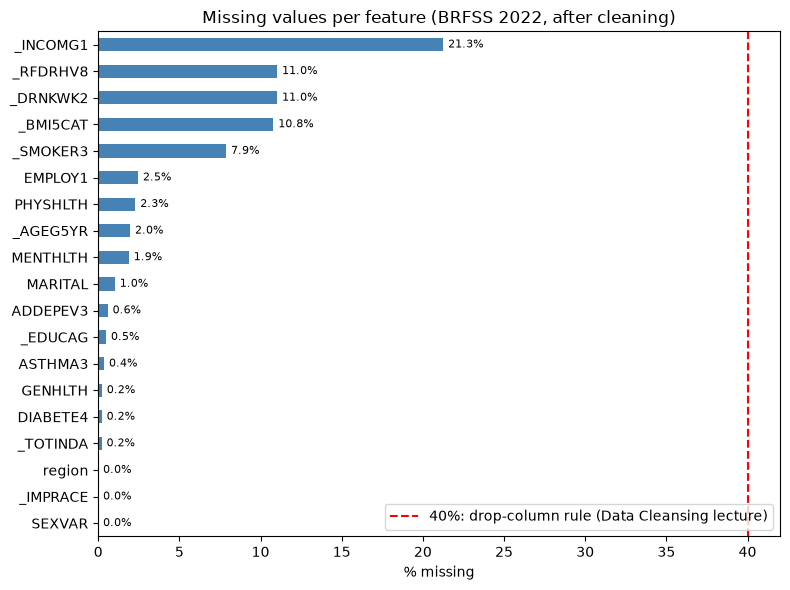

Highest missing: _INCOMG1 (21.3%)
Rows with at least one missing feature: 33.8%
Fully identical rows: 71 (0.016% of the data)


In [ ]:
# How much is missing in each feature after cleaning?
missing_pct = df_clean[GROUP_B_FEATURES].isna().mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
missing_pct.plot.barh(ax=ax, color="steelblue")
ax.axvline(40, color="red", linestyle="--", label="40%: drop-column rule (Data Cleansing lecture)")
for i, v in enumerate(missing_pct):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% missing")
ax.set_title("Missing values per feature (BRFSS 2022, after cleaning)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

rows_with_missing = df_clean[GROUP_B_FEATURES].isna().any(axis=1).mean() * 100
print(f"Highest missing: {missing_pct.idxmax()} ({missing_pct.max():.1f}%)")
print(f"Rows with at least one missing feature: {rows_with_missing:.1f}%")

# Duplicates: rows that are identical in every column, including the survey weight
n_dup = df_clean.duplicated().sum()
print(f"Fully identical rows: {n_dup:,} ({n_dup / len(df_clean):.3%} of the data)")

### Exploratory data analysis
Describes how common short sleep is and how it differs between groups, using tables and plots. This shows the main patterns in the data and how balanced the two classes are, which guides our choice of metrics and models.

In [ ]:
# How common is insufficient sleep in 2022?
# Unweighted = the share in our sample.
# Weighted = uses the survey weight _LLCPWT to correct for groups that are over- or under-represented in the survey,
# so it estimates the share among all adults covered by BRFSS 2022 (50 states, DC and 3 territories).
overall_unweighted = 100 * df_clean["insufficient_sleep"].mean()
overall_weighted = 100 * np.average(df_clean["insufficient_sleep"], weights=df_clean[WEIGHT_COL])
print(f"Sleep less than 7 hours, unweighted: {overall_unweighted:.1f}%  (n = {len(df_clean):,})")
print(f"Sleep less than 7 hours, weighted:   {overall_weighted:.1f}%")

Sleep less than 7 hours, unweighted: 32.8%  (n = 439,679)
Sleep less than 7 hours, weighted:   36.1%


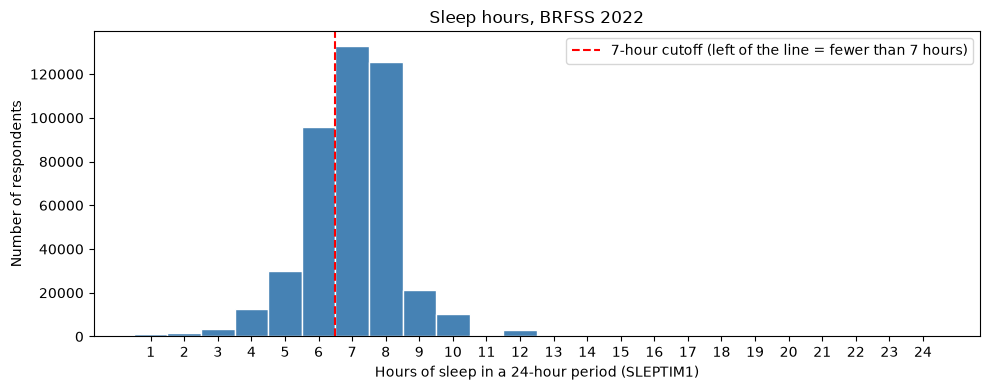

In [ ]:
# Distribution of sleep hours. Bars to the left of the red line (6 hours or fewer) count as insufficient sleep.
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_clean[TARGET_COL], bins=np.arange(0.5, 25.5), color="steelblue", edgecolor="white")
ax.axvline(6.5, color="red", linestyle="--", label="7-hour cutoff (left of the line = fewer than 7 hours)")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Hours of sleep in a 24-hour period (SLEPTIM1)")
ax.set_ylabel("Number of respondents")
ax.set_title("Sleep hours, BRFSS 2022")
ax.legend()
plt.tight_layout()
plt.show()

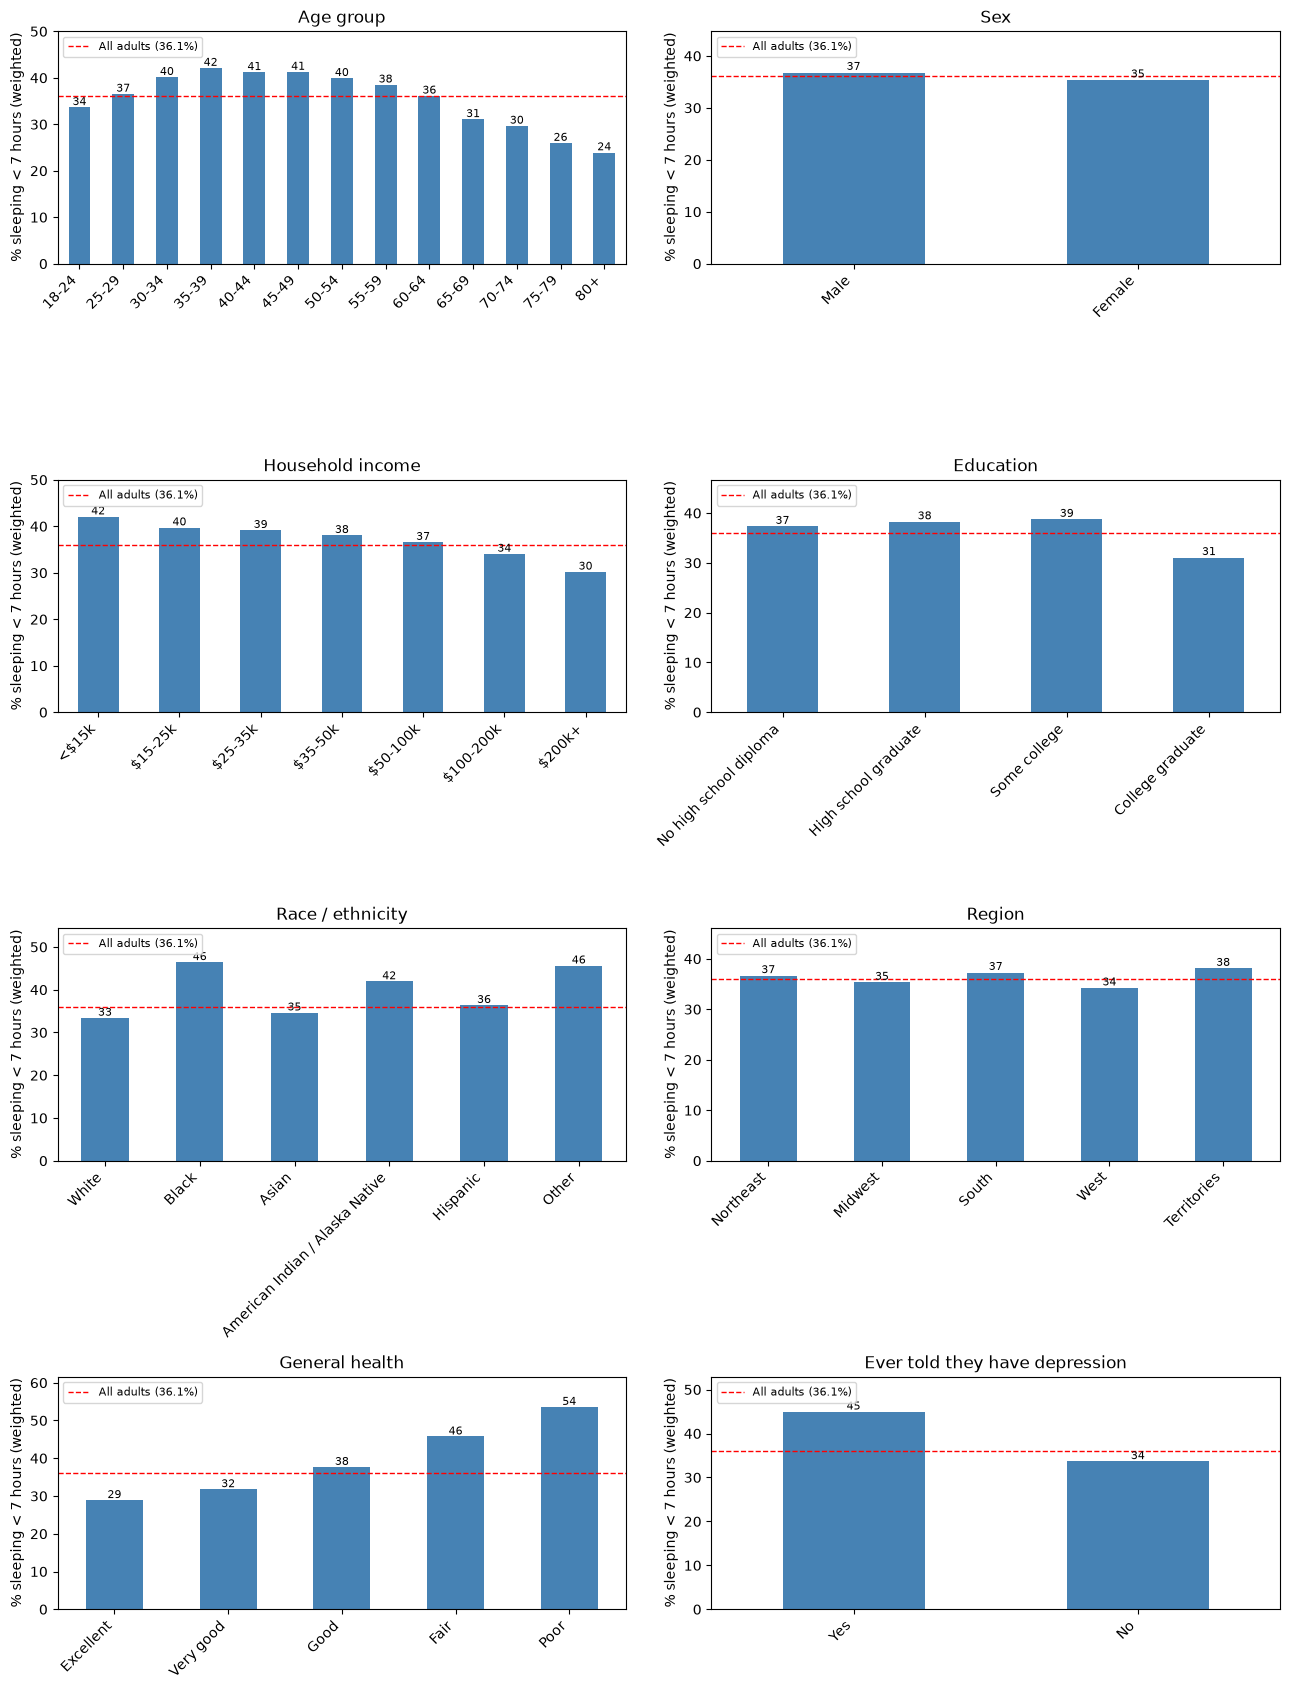

In [ ]:
# Weighted insufficient-sleep rate within each group.
# Category labels come from the 2022 codebook. People with a missing answer are left out of that chart.
LABELS = {
    "_AGEG5YR": {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
                 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"},
    "SEXVAR":   {1: "Male", 2: "Female"},
    "_INCOMG1": {1: "<$15k", 2: "$15-25k", 3: "$25-35k", 4: "$35-50k", 5: "$50-100k", 6: "$100-200k", 7: "$200k+"},
    "_EDUCAG":  {1: "No high school diploma", 2: "High school graduate", 3: "Some college", 4: "College graduate"},
    "_IMPRACE": {1: "White", 2: "Black", 3: "Asian", 4: "American Indian / Alaska Native", 5: "Hispanic", 6: "Other"},
    "GENHLTH":  {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "ADDEPEV3": {1: "Yes", 2: "No"},
}
REGION_ORDER = ["Northeast", "Midwest", "South", "West", "Territories"]

def weighted_rate(data, col):
    """Weighted % of people with insufficient sleep in each category of col."""
    weighted_target = data["insufficient_sleep"] * data[WEIGHT_COL]
    return 100 * weighted_target.groupby(data[col]).sum() / data[WEIGHT_COL].groupby(data[col]).sum()

PANELS = [("_AGEG5YR", "Age group"), ("SEXVAR", "Sex"), ("_INCOMG1", "Household income"),
          ("_EDUCAG", "Education"), ("_IMPRACE", "Race / ethnicity"), ("region", "Region"),
          ("GENHLTH", "General health"), ("ADDEPEV3", "Ever told they have depression")]

fig, axes = plt.subplots(4, 2, figsize=(13, 17))
for ax, (col, title) in zip(axes.flat, PANELS):
    rates = weighted_rate(df_clean, col)
    rates = rates.reindex(REGION_ORDER) if col == "region" else rates.rename(index=LABELS[col])
    rates.plot.bar(ax=ax, color="steelblue")
    ax.axhline(overall_weighted, color="red", linestyle="--", linewidth=1,
               label=f"All adults ({overall_weighted:.1f}%)")
    for i, v in enumerate(rates):
        ax.text(i, v + 0.5, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("% sleeping < 7 hours (weighted)")
    ax.set_ylim(0, rates.max() + 8)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

       Poor mental health days (past 30)  Poor physical health days (past 30)  Alcoholic drinks per week
count                          431370.00                            429593.00                  391190.00
mean                                4.36                                 4.31                       3.05
std                                 8.35                                 8.64                       9.05
min                                 0.00                                 0.00                       0.00
25%                                 0.00                                 0.00                       0.00
50%                                 0.00                                 0.00                       0.23
75%                                 5.00                                 3.00                       2.80
max                                30.00                                30.00                     532.00


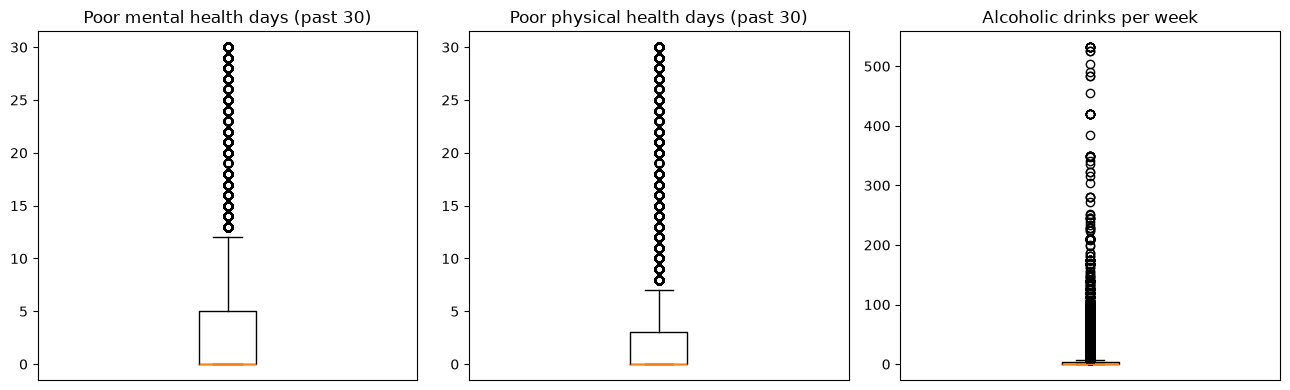

People reporting more than 100 drinks per week (over ~14 a day): 344; maximum = 532


In [ ]:
# Check the numeric features for values that look wrong: compare min / max with the mean and standard deviation,
# and look at the box plots for extreme values (Data Cleansing lecture: outliers).
NUMERIC_LABELS = {"MENTHLTH": "Poor mental health days (past 30)",
                  "PHYSHLTH": "Poor physical health days (past 30)",
                  "_DRNKWK2": "Alcoholic drinks per week"}
print(df_clean[NUMERIC_FEATURES].describe().round(2).rename(columns=NUMERIC_LABELS).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.boxplot(df_clean[col].dropna())
    ax.set_title(NUMERIC_LABELS[col])
    ax.set_xticks([])
plt.tight_layout()
plt.show()

drinks = df_clean["_DRNKWK2"]
print(f"People reporting more than 100 drinks per week (over ~14 a day): {(drinks > 100).sum():,}; maximum = {drinks.max():.0f}")
heavy = drinks > 100
print(f"Short-sleep rate: {100 * df_clean.loc[heavy, 'insufficient_sleep'].mean():.1f}% among them, "
      f"{100 * df_clean.loc[drinks.notna() & ~heavy, 'insufficient_sleep'].mean():.1f}% among everyone else who answered")

#### Decision: we keep the extreme drink values
The check above shows 344 people who report more than 100 drinks per week, with a maximum of 532. We keep them in the data, unchanged becaouse they are real survray answers, they are a few (344), they hardly afect the modes.



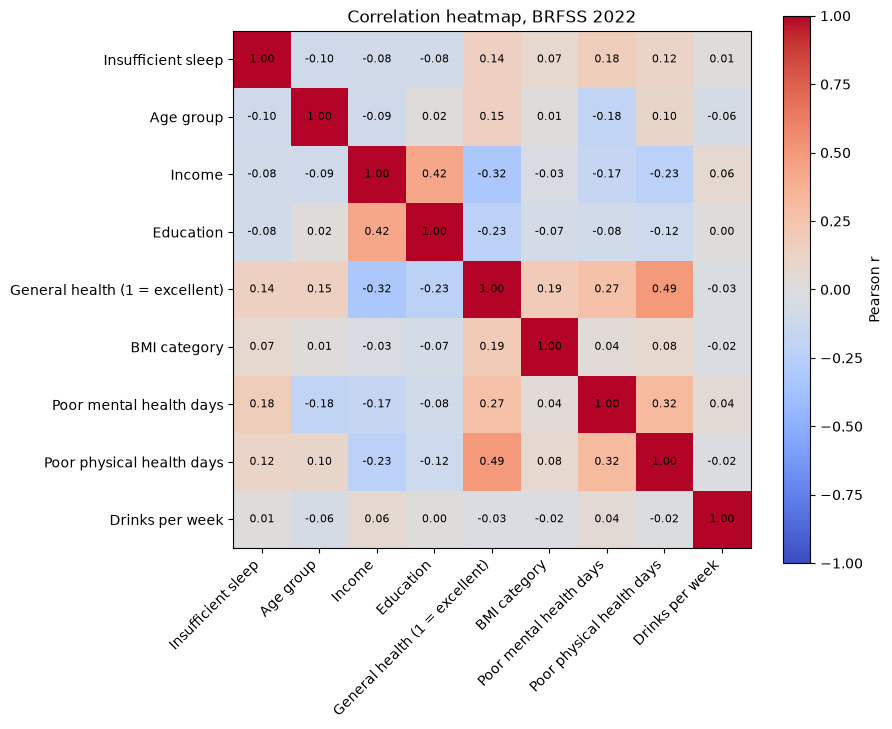

In [ ]:
# Pearson correlation between the numeric and ordered features and the target (Lecture 3).
# For ordered categories (age group, income, ...) the codes are treated as numbers, so this is an approximation.
# Nominal features (sex, race, employment, marital status, region, yes/no conditions) have no order, so they are
# left out here and covered by the chi-square tests below.
CORR_LABELS = {"insufficient_sleep": "Insufficient sleep", "_AGEG5YR": "Age group", "_INCOMG1": "Income",
               "_EDUCAG": "Education", "GENHLTH": "General health (1 = excellent)", "_BMI5CAT": "BMI category",
               "MENTHLTH": "Poor mental health days", "PHYSHLTH": "Poor physical health days",
               "_DRNKWK2": "Drinks per week"}
corr = df_clean[list(CORR_LABELS)].corr().rename(index=CORR_LABELS, columns=CORR_LABELS)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation heatmap, BRFSS 2022")
plt.tight_layout()
plt.show()

In [ ]:
# EXPLORATORY ONLY: chi-square test of independence between each categorical feature and the target.
# These tests describe our sample. They are NOT survey-adjusted inference about the U.S. population:
# the ordinary chi-square test assumes a simple random sample, and BRFSS uses a complex survey design.
# With about 440,000 people almost every p-value is tiny, so we also report Cramer's V
# (0 = no association, 1 = perfect association) to show how strong each association is.
from scipy.stats import chi2_contingency

CATEGORICAL_FEATURES = [c for c in GROUP_B_FEATURES if c not in NUMERIC_FEATURES]
chi_rows = []
for col in CATEGORICAL_FEATURES:
    table = pd.crosstab(df_clean[col], df_clean["insufficient_sleep"])
    chi2, p_value, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    chi_rows.append({"feature": col, "group": "A" if col in GROUP_A_FEATURES else "B",
                     "chi2": chi2, "dof": dof, "p_value": p_value, "cramers_v": cramers_v})

chi_results = pd.DataFrame(chi_rows).sort_values("cramers_v", ascending=False)
print("Exploratory chi-square tests (sample only, not survey-adjusted)")
print(chi_results.to_string(index=False, formatters={"chi2": "{:,.0f}".format, "p_value": "{:.1e}".format,
                                                      "cramers_v": "{:.3f}".format}))

Exploratory chi-square tests (sample only, not survey-adjusted)
 feature group  chi2  dof  p_value cramers_v
 GENHLTH     B 9,147    4  0.0e+00     0.144
 EMPLOY1     A 8,098    7  0.0e+00     0.137
_AGEG5YR     A 6,746   12  0.0e+00     0.125
_IMPRACE     A 4,710    5  0.0e+00     0.104
_SMOKER3     B 3,922    3  0.0e+00     0.098
ADDEPEV3     B 3,712    1  0.0e+00     0.092
 _EDUCAG     A 3,635    3  0.0e+00     0.091
 MARITAL     A 3,547    5  0.0e+00     0.090
_INCOMG1     A 2,331    6  0.0e+00     0.082
_BMI5CAT     B 2,387    3  0.0e+00     0.078
_TOTINDA     B 2,010    1  0.0e+00     0.068
 ASTHMA3     B 1,809    1  0.0e+00     0.064
  region     A   667    4 4.0e-143     0.039
DIABETE4     B   640    3 2.7e-138     0.038
  SEXVAR     A    27    1  2.2e-07     0.008
_RFDRHV8     B    21    1  4.7e-06     0.007


In [ ]:
# Class balance: how many people are in each class? This guides the choice of metrics (Imbalanced Data lecture).
counts = df_clean["insufficient_sleep"].value_counts().sort_index()
shares = 100 * counts / counts.sum()
print(f"Class 0 (7 hours or more):     {counts[0]:,} ({shares[0]:.1f}%)")
print(f"Class 1 (fewer than 7 hours):  {counts[1]:,} ({shares[1]:.1f}%)")
print(f"Ratio: about {counts[0] / counts[1]:.1f} people with enough sleep for every person with insufficient sleep")

Class 0 (7 hours or more):     295,281 (67.2%)
Class 1 (fewer than 7 hours):  144,398 (32.8%)
Ratio: about 2.0 people with enough sleep for every person with insufficient sleep


### Methods
This part describes how we answer the question. We split the data, build a preprocessing pipeline, set a baseline, and train three algorithms on two feature sets with the same settings. All choices are made on the training and validation data, so the test set stays untouched for a fair final evaluation.

###  Data split and preprocessing
Splits the data once into train (60%), validation (20%) and test (20%), so both feature sets use exactly the same people. Missing values are filled and categories are encoded inside a pipeline that is fitted on the training data only, to avoid data leakage.

In [ ]:
# Split the data ONCE into train (60%), validation (20%) and test (20%), stratified by the target.
# Both models use these same rows: Model 1 later takes only the Group A columns, Model 2 takes all columns.
from sklearn.model_selection import train_test_split

X_all = df_clean[GROUP_B_FEATURES]       # all features (Group A is a subset of these columns)
y_all = df_clean["insufficient_sleep"]

# First hold out 20% as the test set, then split the remaining 80% into train and validation
# (25% of 80% = 20% of all data). stratify keeps the same share of short sleepers in every set.
X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    "% of data": [100 * len(s) / len(y_all) for s in (y_train, y_val, y_test)],
    "% insufficient sleep": [100 * s.mean() for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
print(split_summary.round(1).to_string())

# Check: the three sets do not share any respondent
assert not (set(X_train.index) & set(X_val.index) or set(X_train.index) & set(X_test.index)
            or set(X_val.index) & set(X_test.index)), "The sets overlap"
# From here on, the test set is not used until the final evaluation.

              rows  % of data  % insufficient sleep
train       263807       60.0                  32.8
validation   87936       20.0                  32.8
test         87936       20.0                  32.8


In [ ]:
# Preprocessing pipeline: fill missing values, one-hot encode categories and scale numbers.
# It is fitted (learns the most frequent values, medians, means and standard deviations) on the TRAINING data
# only, and then applied unchanged to the validation and test data. This prevents data leakage.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(features):
    """Build the preprocessing steps for a list of features (Group A or Group B)."""
    categorical = [c for c in features if c not in NUMERIC_FEATURES]
    numeric = [c for c in features if c in NUMERIC_FEATURES]
    return ColumnTransformer([
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),     # missing category -> most common answer
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),  # one yes/no column per category
        ]), categorical),
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),            # missing number -> median
            ("scale", StandardScaler()),                             # mean 0, standard deviation 1
        ]), numeric),
    ])

# Check: fit on the training data only and transform train and validation (the test set is not touched)
for name, features in [("Group A (Model 1)", GROUP_A_FEATURES), ("Group B (Model 2)", GROUP_B_FEATURES)]:
    prep = make_preprocessor(features).fit(X_train[features])
    train_ready = prep.transform(X_train[features])
    val_ready = prep.transform(X_val[features])
    print(f"{name}: {len(features)} features -> {train_ready.shape[1]} model columns after one-hot encoding; "
          f"missing values left: train {np.isnan(train_ready).sum()}, validation {np.isnan(val_ready).sum()}")

Group A (Model 1): 8 features -> 51 model columns after one-hot encoding; missing values left: train 0, validation 0
Group B (Model 2): 19 features -> 79 model columns after one-hot encoding; missing values left: train 0, validation 0


### Baseline
A model that always predicts "sufficient sleep", the most common answer. It shows the score we get without learning anything, so we can tell whether our models really help.

In [ ]:
# Baseline: always predict the most common class, 0 = "sufficient sleep". It ignores every feature.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_auc_score)

def evaluate(y_true, y_pred, y_score):
    """The six metrics we report for every model. y_pred = 0/1 predictions, y_score = predicted probability of class 1."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),   # 0 when the model never predicts class 1
        "recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "Average Precision": average_precision_score(y_true, y_score),
    }

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_val = evaluate(y_val, baseline.predict(X_val), baseline.predict_proba(X_val)[:, 1])

print("Baseline on the validation set:")
for metric, value in baseline_val.items():
    print(f"  {metric:<18} {value:.3f}")
print()
print(f"Share of the validation set with sufficient sleep (class 0): {(y_val == 0).mean():.3f}")
print(f"Share of the validation set with insufficient sleep (class 1): {(y_val == 1).mean():.3f}")

Baseline on the validation set:
  accuracy           0.672
  precision          0.000
  recall             0.000
  F1                 0.000
  ROC-AUC            0.500
  Average Precision  0.328

Share of the validation set with sufficient sleep (class 0): 0.672
Share of the validation set with insufficient sleep (class 1): 0.328


###  Model 1: structural variables only (Group A)
Trains and tunes Logistic Regression, Random Forest and Gradient Boosting using only the background variables.


In [ ]:
# Model 1: structural variables only (Group A).
# Each algorithm runs inside a pipeline with the preprocessing from above, so filling, encoding and scaling are
# learned from the training data only.
# Tuning: a random search of 20 combinations from the parameter ranges in our plan. Each combination is trained on
# training data and scored on the validation set with Average Precision (our main metric, because the target is
# imbalanced). To keep the run time reasonable, the search trains on a fixed stratified sample of 50,000 training
# rows (the same sample for Model 1 and Model 2). The best combination is then retrained on the full training set.
import time
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid, PredefinedSplit, RandomizedSearchCV

N_SEARCH = 20                                         # random combinations tried per algorithm
TUNE_SAMPLE_SIZE = 50_000                             # training rows used during the search
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)  # decision thresholds tried on the validation set

# (estimator, parameter ranges, parallel jobs for the search)
# Gradient Boosting uses HistGradientBoostingClassifier: the same boosting idea as GradientBoostingClassifier
# from the lecture, but much faster on 260,000+ rows. It already uses all CPU cores, so its search runs one at a time.
ALGORITHMS = {
    "Logistic Regression": (LogisticRegression(max_iter=1000),
                            {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}, -1),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                      {"n_estimators": [200, 400], "max_depth": [6, 10, 14, 20], "max_features": ["sqrt", "log2"],
                       "min_samples_leaf": [5, 20, 50], "class_weight": [None, "balanced"]}, -1),
    "Gradient Boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=False),
                          {"max_iter": [200, 500, 800], "learning_rate": [0.01, 0.05, 0.1], "max_depth": [3, 5, 7],
                           "class_weight": [None, "balanced"]}, 1),
}

# Fixed tuning sample, shared by Model 1 and Model 2
tune_idx, _ = train_test_split(X_train.index, train_size=TUNE_SAMPLE_SIZE, stratify=y_train,
                               random_state=RANDOM_STATE)

def best_f1_threshold(y_true, proba):
    """The decision threshold (0.05-0.95) with the highest F1 score (Imbalanced Data lecture: threshold tuning)."""
    f1_scores = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in THRESHOLDS]
    return THRESHOLDS[int(np.argmax(f1_scores))]

def tune_models(features):
    """Tune, retrain and evaluate the three algorithms on one feature set (used for Model 1 and Model 2)."""
    # PredefinedSplit: -1 = always used for training (the tuning sample), 0 = used for scoring (validation set)
    X_search = pd.concat([X_train.loc[tune_idx, features], X_val[features]])
    y_search = pd.concat([y_train.loc[tune_idx], y_val])
    train_val_split = PredefinedSplit(np.concatenate([np.full(len(tune_idx), -1), np.zeros(len(y_val))]))

    fitted, rows = {}, []
    for name, (estimator, space, n_jobs) in ALGORITHMS.items():
        start = time.time()
        pipe = Pipeline([("prep", make_preprocessor(features)), ("model", clone(estimator))])
        search = RandomizedSearchCV(pipe, {f"model__{k}": v for k, v in space.items()},
                                    n_iter=min(N_SEARCH, len(ParameterGrid(space))), scoring="average_precision",
                                    cv=train_val_split, refit=False, random_state=RANDOM_STATE, n_jobs=n_jobs)
        search.fit(X_search, y_search)

        # Retrain the best combination on the full training set, then score it
        best = pipe.set_params(**search.best_params_).fit(X_train[features], y_train)
        val_proba = best.predict_proba(X_val[features])[:, 1]
        train_ap = average_precision_score(y_train, best.predict_proba(X_train[features])[:, 1])
        threshold = best_f1_threshold(y_val, val_proba)
        metrics = evaluate(y_val, (val_proba >= threshold).astype(int), val_proba)

        best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
        fitted[name] = {"model": best, "threshold": threshold, "params": best_params}
        rows.append({"algorithm": name, "threshold": threshold, **metrics, "train AP": train_ap,
                     "AP gap (train - val)": train_ap - metrics["Average Precision"]})
        print(f"{name} ({time.time() - start:.0f} s): best settings {best_params}")
    return fitted, pd.DataFrame(rows).set_index("algorithm")

models_A, results_A = tune_models(GROUP_A_FEATURES)

# Validation results. The baseline row is added for comparison (its threshold is not tuned).
baseline_row = pd.DataFrame([{"threshold": np.nan, **baseline_val}], index=["Baseline (always 0)"])
print()
print("Model 1 (Group A) on the validation set; accuracy, precision, recall and F1 use the tuned threshold:")
print(pd.concat([results_A, baseline_row]).round(3).to_string())

Logistic Regression (55 s): best settings {'class_weight': None, 'C': 10}
Random Forest (340 s): best settings {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'log2', 'max_depth': 14, 'class_weight': None}
Gradient Boosting (268 s): best settings {'max_iter': 200, 'max_depth': 3, 'learning_rate': 0.1, 'class_weight': 'balanced'}

Model 1 (Group A) on the validation set; accuracy, precision, recall and F1 use the tuned threshold:
                     threshold  accuracy  precision  recall     F1  ROC-AUC  Average Precision  train AP  AP gap (train - val)
Logistic Regression       0.25     0.459      0.364   0.866  0.513    0.626              0.434     0.435                 0.000
Random Forest             0.27     0.490      0.374   0.819  0.513    0.632              0.444     0.467                 0.024
Gradient Boosting         0.41     0.479      0.371   0.839  0.514    0.633              0.444     0.449                 0.005
Baseline (always 0)        NaN     0.672     

### Model 2: structural + health and lifestyle variables (Group B)
Repeats exactly the same procedure with the health and lifestyle variables added. Because everything else is identical, any difference from Model 1 comes from the added variables.

In [ ]:
# Model 2: structural + health and lifestyle variables (Group A + Group B).
# Exactly the same procedure as Model 1 (same function): the same three algorithms, parameter ranges,
# 20 search tries, tuning sample, train/validation split and F1-based threshold. Only the features change.
models_B, results_B = tune_models(GROUP_B_FEATURES)

print()
print("Model 2 (Group A + B) on the validation set; accuracy, precision, recall and F1 use the tuned threshold:")
print(pd.concat([results_B, baseline_row]).round(3).to_string())

# First look at the gap on the VALIDATION set (the final comparison is on the test set, in the Results part)
gap = pd.DataFrame({
    "ROC-AUC Model 1": results_A["ROC-AUC"], "ROC-AUC Model 2": results_B["ROC-AUC"],
    "ROC-AUC gain": results_B["ROC-AUC"] - results_A["ROC-AUC"],
    "AP Model 1": results_A["Average Precision"], "AP Model 2": results_B["Average Precision"],
    "AP gain": results_B["Average Precision"] - results_A["Average Precision"],
})
print()
print("Model 2 vs. Model 1 on the validation set:")
print(gap.round(3).to_string())

Logistic Regression (63 s): best settings {'class_weight': None, 'C': 10}
Random Forest (541 s): best settings {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 14, 'class_weight': 'balanced'}
Gradient Boosting (576 s): best settings {'max_iter': 500, 'max_depth': 3, 'learning_rate': 0.05, 'class_weight': 'balanced'}

Model 2 (Group A + B) on the validation set; accuracy, precision, recall and F1 use the tuned threshold:
                     threshold  accuracy  precision  recall     F1  ROC-AUC  Average Precision  train AP  AP gap (train - val)
Logistic Regression       0.26     0.530      0.392   0.788  0.524    0.660              0.486     0.486                -0.000
Random Forest             0.43     0.536      0.396   0.787  0.527    0.664              0.491     0.591                 0.100
Gradient Boosting         0.41     0.531      0.394   0.799  0.528    0.667              0.495     0.501                 0.006
Baseline (always 0)        NaN     

## Results


### Test results: Model 1 vs. Model 2
Evaluates all six models (3 algorithms × 2 feature sets) once on the untouched test set, using the settings and decision thresholds chosen on the validation set. The gap between Model 2 and Model 1 within each algorithm is the answer to our research question.

In [ ]:
# FINAL EVALUATION: the test set is used here for the first and only time.
# Every model keeps the settings and the decision threshold chosen on the validation set.
FEATURE_SETS = {"Model 1": (GROUP_A_FEATURES, models_A), "Model 2": (GROUP_B_FEATURES, models_B)}
ALGORITHM_ORDER = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
METRICS = ["accuracy", "precision", "recall", "F1", "ROC-AUC", "Average Precision"]

test_rows, test_proba, test_pred = [], {}, {}
for model_name, (features, fitted) in FEATURE_SETS.items():
    for algo in ALGORITHM_ORDER:
        proba = fitted[algo]["model"].predict_proba(X_test[features])[:, 1]
        pred = (proba >= fitted[algo]["threshold"]).astype(int)
        test_proba[(model_name, algo)], test_pred[(model_name, algo)] = proba, pred
        test_rows.append({"algorithm": algo, "model": model_name, "threshold": fitted[algo]["threshold"],
                          **evaluate(y_test, pred, proba)})
test_results = pd.DataFrame(test_rows).set_index(["algorithm", "model"]).loc[ALGORITHM_ORDER]

baseline_test = evaluate(y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:, 1])
print("All six models on the TEST set (accuracy, precision, recall and F1 use the threshold chosen on validation):")
print(test_results.round(3).to_string())
print()
print("Baseline (always 0) on the test set: " + ", ".join(f"{m} {v:.3f}" for m, v in baseline_test.items()))

# Main table: Model 1 score, Model 2 score and the difference, within each algorithm
main_table = pd.concat({
    algo: pd.DataFrame({"Model 1": test_results.loc[(algo, "Model 1"), METRICS],
                        "Model 2": test_results.loc[(algo, "Model 2"), METRICS]})
    for algo in ALGORITHM_ORDER
}, names=["algorithm", "metric"])
main_table["Difference (2 - 1)"] = main_table["Model 2"] - main_table["Model 1"]
print()
print("MAIN TABLE - Model 2 vs. Model 1 on the test set, within each algorithm:")
print(main_table.astype(float).round(3).to_string())

All six models on the TEST set (accuracy, precision, recall and F1 use the threshold chosen on validation):
                             threshold  accuracy  precision  recall     F1  ROC-AUC  Average Precision
algorithm           model                                                                             
Logistic Regression Model 1       0.25     0.456      0.362   0.862  0.510    0.625              0.435
                    Model 2       0.26     0.531      0.393   0.789  0.525    0.660              0.488
Random Forest       Model 1       0.27     0.490      0.374   0.816  0.513    0.632              0.446
                    Model 2       0.43     0.537      0.397   0.788  0.528    0.666              0.494
Gradient Boosting   Model 1       0.41     0.478      0.370   0.839  0.514    0.633              0.446
                    Model 2       0.41     0.531      0.394   0.801  0.529    0.667              0.496

Baseline (always 0) on the test set: accuracy 0.672, precision 0.00

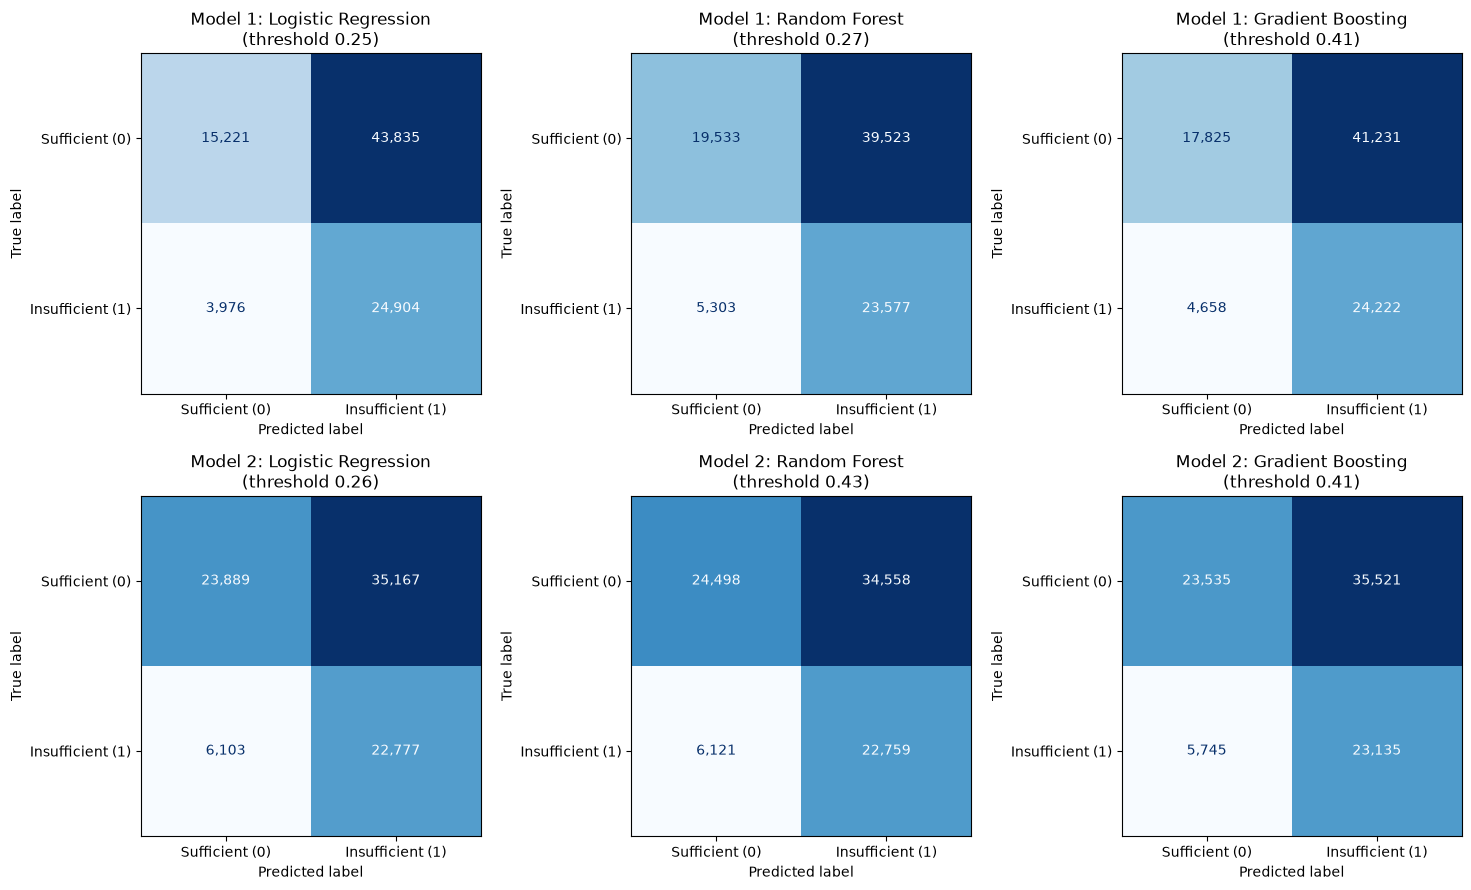

In [ ]:
# Confusion matrices on the test set (rows = true class, columns = predicted class)
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, model_name in enumerate(FEATURE_SETS):
    for col, algo in enumerate(ALGORITHM_ORDER):
        ConfusionMatrixDisplay.from_predictions(
            y_test, test_pred[(model_name, algo)], display_labels=["Sufficient (0)", "Insufficient (1)"],
            values_format=",", cmap="Blues", colorbar=False, ax=axes[row, col])
        axes[row, col].set_title(f"{model_name}: {algo}\n(threshold {FEATURE_SETS[model_name][1][algo]['threshold']:.2f})")
plt.tight_layout()
plt.show()

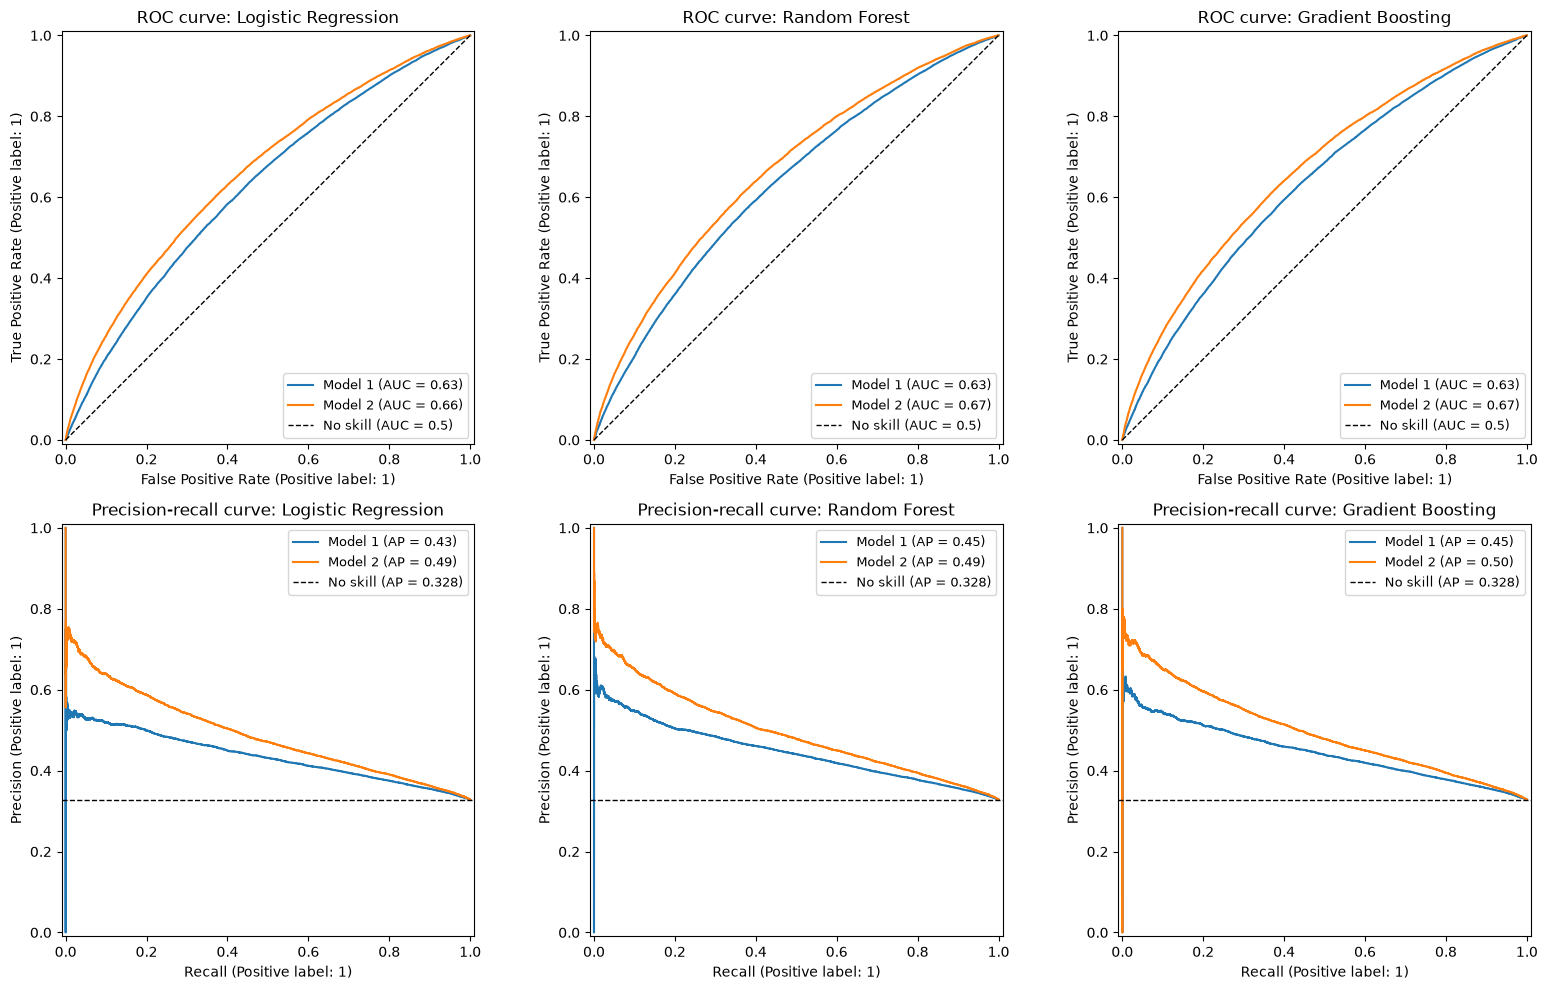

In [ ]:
# ROC curves (top) and precision-recall curves (bottom): Model 1 vs. Model 2 for each algorithm, on the test set.
# Dashed lines show a model with no skill: the diagonal for ROC, and the share of short sleepers for precision-recall.
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for col, algo in enumerate(ALGORITHM_ORDER):
    for model_name, color in [("Model 1", "tab:blue"), ("Model 2", "tab:orange")]:
        proba = test_proba[(model_name, algo)]
        RocCurveDisplay.from_predictions(y_test, proba, name=model_name, curve_kwargs={"color": color}, ax=axes[0, col])
        PrecisionRecallDisplay.from_predictions(y_test, proba, name=model_name, curve_kwargs={"color": color}, ax=axes[1, col])
    axes[0, col].plot([0, 1], [0, 1], "k--", linewidth=1, label="No skill (AUC = 0.5)")
    axes[1, col].axhline(y_test.mean(), color="k", linestyle="--", linewidth=1,
                         label=f"No skill (AP = {y_test.mean():.3f})")
    axes[0, col].set_title(f"ROC curve: {algo}")
    axes[1, col].set_title(f"Precision-recall curve: {algo}")
    for ax in axes[:, col]:
        ax.legend(loc="lower right" if ax in axes[0] else "upper right", fontsize=9)
plt.tight_layout()
plt.show()

### Description of the findings
**1. Pipeline validation (BRFSS 2020).** Applied to the 50 states and DC (390,193 respondents), our target definition and survey weights give a weighted prevalence of insufficient sleep of 32.7%, the same as the CDC's published crude prevalence (difference: +0.02 percentage points). Without the weights the prevalence is 30.5%.

**2. The 2022 data.** After cleaning, 439,679 respondents remain. Income has the most missing answers (21.3%); 33.8% of respondents have at least one missing feature. 32.8% of respondents sleep less than 7 hours (36.1% with the survey weights), so the two classes are split about 67% to 33%.

**3. Differences between groups (weighted).**
- *Age:* the rate is highest at ages 35–39 (42%) and lowest at 80 and older (24%).
- *Income:* it falls from 42% (under $15,000) to 30% ($200,000 or more).
- *Education:* college graduates 31%, other groups 37–39%.
- *Race/ethnicity:* Black 46%, Other 46%, American Indian / Alaska Native 42%, Hispanic 36%, Asian 35%, White 33%.
- *Sex and region:* small differences (men 37%, women 35%; regions 34–38%).
- *General health:* from 29% (excellent) to 54% (poor).
- *Depression:* 45% among people ever told they have depression, 34% among others.
- *Alcohol:* the 344 people who report more than 100 drinks a week have a rate of 55.8%, compared with 32.7% among everyone else who answered.

**4. Associations.** Every Pearson correlation with the target is below 0.2 in absolute value; the largest are poor mental health days (0.18), general health (0.14) and poor physical health days (0.12). In the exploratory chi-square tests, all p-values are very small, and Cramér's V ranges from 0.144 (general health), 0.137 (employment) and 0.125 (age) down to 0.008 (sex) and 0.007 (heavy drinking).

**5. Baseline.** Always predicting "sufficient sleep" gives an accuracy of 0.672, precision, recall and F1 of 0, ROC-AUC 0.500 and Average Precision 0.328, on both the validation and the test set.

**6. Model 1 and Model 2 on the validation set.**
- Model 1 (Group A): ROC-AUC 0.626–0.633 and Average Precision 0.434–0.444.
- Model 2 (Group A + B): ROC-AUC 0.660–0.667 and Average Precision 0.486–0.495.
- The difference between train and validation Average Precision is at most 0.024 for all models, except Random Forest in Model 2 (0.100).
- The F1-based thresholds range from 0.25 to 0.43.

**7. Model 1 vs. Model 2 on the test set (main result).**

| Algorithm | ROC-AUC Model 1 | ROC-AUC Model 2 | Difference | AP Model 1 | AP Model 2 | Difference |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.625 | 0.660 | +0.034 | 0.435 | 0.488 | +0.053 |
| Random Forest | 0.632 | 0.666 | +0.034 | 0.446 | 0.494 | +0.048 |
| Gradient Boosting | 0.633 | 0.667 | +0.034 | 0.446 | 0.496 | +0.050 |

- With every algorithm, Model 2 has higher ROC-AUC (+0.034) and Average Precision (+0.048 to +0.053) than Model 1.
- At the thresholds chosen on validation, Model 2 also has higher F1 (0.525–0.529 vs. 0.510–0.514), precision (0.393–0.397 vs. 0.362–0.374) and accuracy (0.531–0.537 vs. 0.456–0.490), and lower recall (0.788–0.801 vs. 0.816–0.862).
- All test ROC-AUC and Average Precision values are within 0.003 of the validation values.
- The full table with all six metrics is in the output of the test-results cell.

**8. Confusion matrices and curves.** All six models predict "insufficient sleep" for most respondents. For example, Model 2 Gradient Boosting correctly identifies 23,135 of the 28,880 short sleepers (5,745 missed) and labels 35,521 of the 59,056 people who sleep enough as short sleepers. The ROC and precision–recall curves of Model 2 lie above those of Model 1 for all three algorithms, and all curves lie above the no-skill lines.

## Discussion

### Discussion

The results show that structural characteristics alone provide a real but limited ability to predict insufficient sleep. Across the three algorithms, Model 1 achieved ROC-AUC values of about 0.63 and Average Precision values of about 0.44, compared with a baseline ROC-AUC of 0.50 and Average Precision of 0.328.

Adding the health and lifestyle variables consistently improved prediction. Model 2 increased ROC-AUC by about 0.034 and Average Precision by about 0.05 for all three algorithms. The best results were obtained by Gradient Boosting, with a ROC-AUC of 0.667 and Average Precision of 0.496. However, the three algorithms produced very similar results, suggesting that the improvement mainly came from the additional health and lifestyle information rather than from the choice of algorithm.

Overall, the answer to our research question is that structural characteristics contain meaningful information about insufficient sleep, but they are not enough for strong individual-level prediction. Health and lifestyle variables add useful predictive information, although the improvement is moderate rather than dramatic. Even the extended model reaches only about 0.66–0.67 ROC-AUC, so a large part of the variation in insufficient sleep remains unexplained by the variables available in BRFSS.

Our approach was appropriate for this question because both feature sets were evaluated using the same respondents, the same train-validation-test split and the same algorithms. Model settings and decision thresholds were selected using the validation set, while the final comparison was performed on the held-out test set. The close agreement between validation and test performance also suggests that the conclusions were not strongly overfitted to the validation data.

There are several limitations. BRFSS is based on self-reported data, so both sleep duration and health variables may contain reporting error. Some variables contain missing values, and the race/ethnicity variable is partly imputed by the CDC. Survey weights were used for descriptive prevalence estimates but not for model training, so the predictive results should not automatically be interpreted as nationally representative performance. In addition, BRFSS is cross-sectional, so the results show associations and predictive relationships rather than causality. Some health variables may be consequences of poor sleep rather than causes of it, and unmeasured confounding factors may affect both sleep and health.

If we continued the project, we would evaluate the models on another BRFSS year or an external dataset, examine approaches that incorporate survey weights into model evaluation, and test thresholds that reflect the real cost of false positives and false negatives. Longitudinal data and more objective sleep measurements would also help determine whether the observed relationships are stable over time and clarify the direction of the relationships between health and insufficient sleep.